# Lesson 3 — The training loop: train your own agent

In this lesson you learn:

1. What one piece of experience (a **transition**) is.
2. **Replay memory**: why the agent learns from old, random experience.
3. The **Bellman target**: the "correct answer" that the network learns.
4. **Loss** and one **gradient step**: how the weights change.
5. The full loop of `train.py`. You train an agent in about **5 minutes**.

Source file for this lesson: `train.py`. Do Lessons 1 and 2 first.

---

**🇻🇳 Bài 3 — Vòng lặp huấn luyện: tự huấn luyện agent của bạn**

Trong bài này bạn học:

1. Một mẩu kinh nghiệm (một **transition** — bước chuyển) là gì.
2. **Bộ nhớ phát lại (replay memory)**: tại sao agent học từ kinh nghiệm cũ, chọn ngẫu nhiên.
3. **Mục tiêu Bellman (Bellman target)**: "đáp án đúng" mà mạng học theo.
4. **Hàm mất mát (loss)** và một **bước gradient**: trọng số thay đổi như thế nào.
5. Toàn bộ vòng lặp của `train.py`. Bạn huấn luyện một agent trong khoảng **5 phút**.

File mã nguồn của bài này: `train.py`. Hãy làm Bài 1 và Bài 2 trước.

In [1]:
# Setup: find the project folder, so that "import src..." works from this notebook.
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
print("Project folder:", ROOT)

Project folder: /Users/phuonghqh/Documents/working/Tetris-deep-Q-learning-pytorch


In [2]:
import random
import time
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from src.tetris import Tetris
from src.deep_q_network import DeepQNetwork
from src.model_io import load_model
from nb_utils import evaluate, random_policy, greedy_policy, feature_sweep

## Part 1 — One transition

After each move, the agent stores 4 things: `[state, reward, next_state, done]`.

- `state` = the 4 features of the board **before** the move
- `reward` = the reward of the move
- `next_state` = the 4 features of the afterstate that the agent chose
- `done` = `True` if the move ended the game

---

**🇻🇳 Phần 1 — Một transition**

Sau mỗi nước đi, agent lưu 4 thứ: `[state, reward, next_state, done]`.

- `state` = 4 đặc trưng của bàn chơi **trước** nước đi
- `reward` = phần thưởng của nước đi
- `next_state` = 4 đặc trưng của afterstate mà agent đã chọn
- `done` = `True` nếu nước đi làm kết thúc ván

In [3]:
torch.manual_seed(123)
random.seed(123)
env = Tetris()
model = DeepQNetwork()

state = env.reset()
actions, states = zip(*env.get_next_states().items())
states = torch.stack(states)
with torch.no_grad():
    index = torch.argmax(model(states)[:, 0]).item()
next_state = states[index]
reward, done = env.step(actions[index], render=False)

print("state     :", state.tolist(), "(empty board)")
print("action    :", actions[index])
print("reward    :", reward)
print("next_state:", next_state.tolist())
print("done      :", done)

state     : [0.0, 0.0, 0.0, 0.0] (empty board)
action    : (0, 2)
reward    : 1
next_state: [0.0, 2.0, 2.0, 6.0]
done      : False


## Part 2 — Replay memory

`train.py` keeps the last 30,000 transitions in a `deque` (a list with a maximum length).
When the deque is full, the oldest item goes out. For each training step, the agent takes **512 random** transitions.

**Why random?** Moves of one game are very similar. If the network learns only from the last moves,
it forgets old lessons. Random samples from many games give a balanced lesson.

---

**🇻🇳 Phần 2 — Bộ nhớ phát lại (replay memory)**

`train.py` giữ 30.000 transition gần nhất trong một `deque` (một danh sách có độ dài tối đa).
Khi deque đầy, phần tử cũ nhất bị loại ra. Ở mỗi bước huấn luyện, agent lấy **512 transition ngẫu nhiên**.

**Tại sao ngẫu nhiên?** Các nước đi trong cùng một ván rất giống nhau. Nếu mạng chỉ học từ những nước đi mới nhất,
nó sẽ quên các bài học cũ. Mẫu ngẫu nhiên từ nhiều ván cho một bài học cân bằng.

In [4]:
demo = deque(maxlen=5)
for i in range(8):
    demo.append(f"move {i}")
print("memory (max 5):", list(demo))
print("random sample of 3:", random.sample(list(demo), 3))

memory (max 5): ['move 3', 'move 4', 'move 5', 'move 6', 'move 7']
random sample of 3: ['move 4', 'move 7', 'move 6']


## Part 3 — The Bellman target

The network must learn the **value** of a board: "how much reward will I get from here?".
We do not know the true value. So we use this target:

- if the game ended: `target = reward`
- else: `target = reward + gamma × value(next_state)`

**gamma (γ = 0.99)** is the **discount factor**: a future reward counts a little less than a reward now.

When the game ends, the target has no future part. So boards that end the game get a low value.
**That is the real penalty for game over.**

`train.py` writes this as `reward if done else reward + gamma * prediction`.
We write the same rule with numbers: `reward + gamma * value * (1 - done)`.

---

**🇻🇳 Phần 3 — Mục tiêu Bellman**

Mạng phải học **giá trị** của một bàn chơi: "từ đây tôi sẽ nhận được bao nhiêu phần thưởng?".
Ta không biết giá trị thật. Vì vậy ta dùng mục tiêu này:

- nếu ván đã kết thúc: `target = reward`
- nếu không: `target = reward + gamma × value(next_state)`

**gamma (γ = 0.99)** là **hệ số chiết khấu (discount factor)**: phần thưởng trong tương lai được tính ít hơn một chút so với phần thưởng hiện tại.

Khi ván kết thúc, mục tiêu không có phần tương lai. Vì vậy những bàn chơi làm kết thúc ván nhận giá trị thấp.
**Đó là hình phạt thật sự khi thua.**

`train.py` viết điều này là `reward if done else reward + gamma * prediction`.
Ta viết cùng quy tắc đó bằng số: `reward + gamma * value * (1 - done)`.

In [6]:
gamma = 0.99
rewards     = torch.tensor([[1.], [11.], [1.]])
next_values = torch.tensor([[50.], [40.], [30.]])   # the network's guess for each next_state
dones       = torch.tensor([[0.], [0.], [1.]])      # the 3rd move ended the game
targets = rewards + gamma * next_values * (1 - dones)
print(targets)

tensor([[50.5000],
        [50.6000],
        [ 1.0000]])


## Part 4 — Loss and one gradient step

- **Loss:** a number that tells how wrong the network is. We use **MSE** (mean squared error):
  the average of `(prediction − target)²`.
- `optimizer.zero_grad()` removes the old gradients.
- `loss.backward()` calculates, for each weight, how it changes the loss (**backpropagation**).
- `optimizer.step()` changes the weights a little, to make the loss smaller (**Adam** optimizer).

We collect transitions from 5 random games, calculate the targets one time, and do 30 steps.
The loss goes down, but not at every step. Small jumps are normal.

---

**🇻🇳 Phần 4 — Hàm mất mát và một bước gradient**

- **Loss (mất mát):** một con số cho biết mạng sai bao nhiêu. Ta dùng **MSE** (sai số bình phương trung bình):
  trung bình của `(dự đoán − mục tiêu)²`.
- `optimizer.zero_grad()` xóa các gradient cũ.
- `loss.backward()` tính, cho mỗi trọng số, nó làm loss thay đổi thế nào (**lan truyền ngược — backpropagation**).
- `optimizer.step()` thay đổi trọng số một chút để loss nhỏ hơn (bộ tối ưu **Adam**).

Ta thu thập transition từ 5 ván ngẫu nhiên, tính mục tiêu một lần, và chạy 30 bước.
Loss giảm dần, nhưng không phải bước nào cũng giảm. Những bước nhảy nhỏ là bình thường.

In [7]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

memory = []
for _ in range(5):
    state, done = env.reset(), False
    while not done:
        actions, states = zip(*env.get_next_states().items())
        i = random.randrange(len(actions))
        reward, done = env.step(actions[i], render=False)
        memory.append([state, reward, states[i], done])
        state = states[i]

s, r, ns, d = zip(*memory)
s, ns = torch.stack(s), torch.stack(ns)
r = torch.tensor(r, dtype=torch.float32)[:, None]
d = torch.tensor(d, dtype=torch.float32)[:, None]
with torch.no_grad():
    y = r + gamma * model(ns) * (1 - d)

print("transitions:", len(memory))
for step in range(30):
    loss = criterion(model(s), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 3 == 0 or step == 29:
        print(f"step {step:>2}: loss = {loss.item():.3f}")

transitions: 108
step  0: loss = 4.838
step  3: loss = 4.498
step  6: loss = 3.923
step  9: loss = 4.179
step 12: loss = 3.666
step 15: loss = 3.556
step 18: loss = 3.670
step 21: loss = 3.445
step 24: loss = 3.426
step 27: loss = 3.430
step 29: loss = 3.324


In real training the targets change too, because the network makes them (this is **bootstrapping**).
So in RL, the loss is not a good progress measure. We measure the game results: pieces, lines, score.

## Part 5 — The full training loop

This is the loop of `train.py`, with 3 small changes:

1. No game window (`render=False`), so it is much faster.
2. A limit of `max_pieces` per game. When a game reaches the limit, we stop it, but we do **not** mark it as `done`.
   The board was not lost, so its future value is still real. (RL calls this **truncation**, not termination.)
3. The target uses the `(1 - done)` form from Part 3.

**1 epoch = 1 game = 1 training step.** Training starts when the memory has 3,000 transitions.

⏱ This cell takes about **5 minutes**. For a quick test, set `num_epochs` to 1000 (the agent will learn less).

---

🇻🇳 Trong huấn luyện thật, mục tiêu cũng thay đổi, vì chính mạng tạo ra chúng (đây gọi là **bootstrapping**).
Vì vậy trong RL, loss không phải là thước đo tiến bộ tốt. Ta đo kết quả chơi: số mảnh, số hàng, điểm.

**🇻🇳 Phần 5 — Toàn bộ vòng lặp huấn luyện**

Đây là vòng lặp của `train.py`, với 3 thay đổi nhỏ:

1. Không có cửa sổ trò chơi (`render=False`), nên nhanh hơn nhiều.
2. Giới hạn `max_pieces` mảnh mỗi ván. Khi một ván đạt giới hạn, ta dừng nó, nhưng **không** đánh dấu là `done`.
   Bàn chơi chưa thua, nên giá trị tương lai của nó vẫn có thật. (RL gọi đây là **cắt ngắn — truncation**, không phải **kết thúc — termination**.)
3. Mục tiêu dùng dạng `(1 - done)` từ Phần 3.

**1 epoch = 1 ván = 1 bước huấn luyện.** Huấn luyện bắt đầu khi bộ nhớ có 3.000 transition.

⏱ Ô này chạy khoảng **5 phút**. Để thử nhanh, đặt `num_epochs` thành 1000 (agent sẽ học được ít hơn).

In [8]:
HP = dict(lr=1e-3, gamma=0.99, batch_size=512, replay_memory_size=30000,
          initial_epsilon=1.0, final_epsilon=1e-3, num_decay_epochs=2000, num_epochs=3000,
          max_pieces=500)

In [10]:
torch.manual_seed(123)
random.seed(123)
env = Tetris()
model = DeepQNetwork()
optimizer = torch.optim.Adam(model.parameters(), lr=HP["lr"])
criterion = nn.MSELoss()
memory = deque(maxlen=HP["replay_memory_size"])
history = []                       # one row per game: (epoch, score, pieces, lines)

state = env.reset()
epoch, start = 0, time.time()
while epoch < HP["num_epochs"]:
    # 1. Epsilon: the probability of a random move (train.py lines 66-67)
    epsilon = HP["final_epsilon"] + max(HP["num_decay_epochs"] - epoch, 0) * (
        HP["initial_epsilon"] - HP["final_epsilon"]) / HP["num_decay_epochs"]

    # 2. Choose an action: random, or the afterstate with the highest value (lines 70-84)
    actions, states = zip(*env.get_next_states().items())
    states = torch.stack(states)
    if random.random() <= epsilon:
        index = random.randint(0, len(actions) - 1)
    else:
        with torch.no_grad():
            index = torch.argmax(model(states)[:, 0]).item()
    next_state = states[index]

    # 3. Do the move and store the transition (lines 86-90)
    reward, done = env.step(actions[index], render=False)
    memory.append([state, reward, next_state, done])
    if not done and env.tetrominoes < HP["max_pieces"]:
        state = next_state
        continue

    # 4. The game ended: keep its results and start a new game (lines 91-97)
    history.append((epoch, env.score, env.tetrominoes, env.cleared_lines))
    state = env.reset()
    if len(memory) < HP["replay_memory_size"] / 10:
        continue

    # 5. One training step on a random batch (lines 103-128)
    epoch += 1
    batch = random.sample(memory, min(len(memory), HP["batch_size"]))
    s, r, ns, d = zip(*batch)
    s, ns = torch.stack(s), torch.stack(ns)
    r = torch.tensor(r, dtype=torch.float32)[:, None]
    d = torch.tensor(d, dtype=torch.float32)[:, None]
    with torch.no_grad():
        y = r + HP["gamma"] * model(ns) * (1 - d)
    loss = criterion(model(s), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 250 == 0:
        last = np.array(history[-20:])
        print(f"epoch {epoch:>4}  epsilon={epsilon:.2f}  last 20 games: pieces={last[:, 2].mean():6.1f}"
              f"  lines={last[:, 3].mean():6.1f}  time={time.time() - start:4.0f}s")

epoch  250  epsilon=0.88  last 20 games: pieces=  20.1  lines=   0.1  time=   6s
epoch  500  epsilon=0.75  last 20 games: pieces=  20.4  lines=   0.0  time=  11s
epoch  750  epsilon=0.63  last 20 games: pieces=  23.1  lines=   0.3  time=  16s
epoch 1000  epsilon=0.50  last 20 games: pieces=  30.6  lines=   1.2  time=  22s
epoch 1250  epsilon=0.38  last 20 games: pieces=  31.4  lines=   0.9  time=  28s
epoch 1500  epsilon=0.25  last 20 games: pieces=  39.1  lines=   3.4  time=  36s
epoch 1750  epsilon=0.13  last 20 games: pieces=  47.8  lines=   5.2  time=  46s
epoch 2000  epsilon=0.00  last 20 games: pieces= 152.8  lines=  46.8  time=  67s
epoch 2250  epsilon=0.00  last 20 games: pieces= 181.8  lines=  61.2  time= 120s
epoch 2500  epsilon=0.00  last 20 games: pieces= 361.4  lines= 133.9  time= 173s
epoch 2750  epsilon=0.00  last 20 games: pieces= 248.1  lines=  88.3  time= 240s
epoch 3000  epsilon=0.00  last 20 games: pieces= 462.6  lines= 176.2  time= 300s


## Part 6 — The training curves

These are the same 3 measures that `train.py` writes to TensorBoard: score, pieces (tetrominoes), and cleared lines.
The light line is each game. The dark line is the average of the last 50 games.

---

**🇻🇳 Phần 6 — Đường cong huấn luyện**

Đây là 3 thước đo giống như `train.py` ghi vào TensorBoard: điểm, số mảnh (tetrominoes) và số hàng đã xóa.
Đường nhạt là từng ván. Đường đậm là trung bình của 50 ván gần nhất.

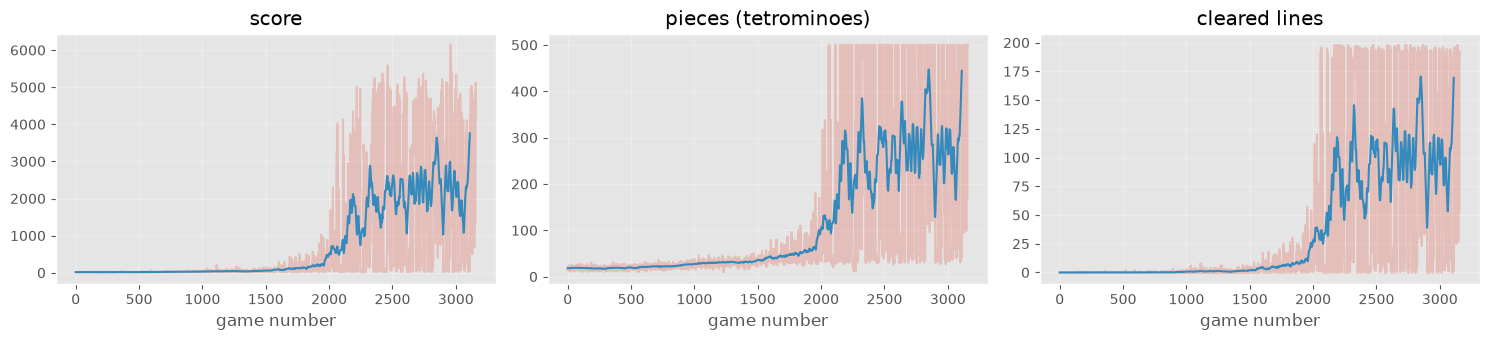

In [11]:
h = np.array(history)
window = 50
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, name in zip(axes, (1, 2, 3), ("score", "pieces (tetrominoes)", "cleared lines")):
    ax.plot(h[:, col], alpha=0.25)
    ax.plot(np.convolve(h[:, col], np.ones(window) / window, mode="valid"))
    ax.set_title(name)
    ax.set_xlabel("game number")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Questions:** When does the curve start to go up? Compare it with the epsilon curve of Lesson 2.
Why does the curve stay flat while epsilon is high?

## Part 7 — Test your agent

No exploration now: the agent always takes the best move.

---

🇻🇳 **Câu hỏi:** Khi nào đường cong bắt đầu đi lên? So sánh với đường epsilon ở Bài 2.
Tại sao đường cong nằm ngang khi epsilon còn cao?

**🇻🇳 Phần 7 — Kiểm tra agent của bạn**

Bây giờ không còn khám phá: agent luôn chọn nước đi tốt nhất.

In [ ]:
model.eval()
print(f"{'random':<20}", evaluate(random_policy, games=5, max_pieces=500))
print(f"{'your network':<20}", evaluate(greedy_policy(model), games=5, max_pieces=500))
try:
    print(f"{'pre-trained (author)':<20}", evaluate(greedy_policy(load_model('trained_models/tetris')), games=5, max_pieces=500))
except RuntimeError as error:
    print("pre-trained model not available:", str(error).splitlines()[0])

In [ ]:
feature_sweep(model)

## Part 8 — Save your model and watch it play

We save to `my_models/`, so the model of the author in `trained_models/` does not change.

---

**🇻🇳 Phần 8 — Lưu mô hình và xem nó chơi**

Ta lưu vào `my_models/`, để mô hình của tác giả trong `trained_models/` không bị thay đổi.

In [ ]:
os.makedirs("my_models", exist_ok=True)
torch.save(model, "my_models/tetris")
print("saved: my_models/tetris")

To watch your agent in a window, run this in a terminal:

```
uv run python test.py --saved_path my_models
```

---

🇻🇳 Để xem agent của bạn chơi trong cửa sổ, chạy lệnh ở trên trong terminal.

## Part 9 — More experiments

Change one thing, run Part 5 again, and compare the curves. Write down your results.

1. `gamma=0.5`: the agent becomes "short-sighted". What happens to the cleared lines?
2. `num_decay_epochs=200`: the agent stops exploring early. Is the final result worse?
3. `batch_size=32`: smaller batches. Is training less stable?
4. Remove the `holes` feature: in `src/tetris.py` line 87 and in `src/deep_q_network.py` line 10 (`Linear(3, 64)`).

### The full `train.py`

```
mkdir -p my_models
uv run python train.py --saved_path my_models
uv run tensorboard --logdir tensorboard
```

⚠️ Always use `--saved_path my_models`. With the default path, `train.py` overwrites the model of the author in `trained_models/tetris`.
`train.py` draws every move in a window, so it is much slower than this notebook.

## Summary

- The agent stores transitions `[state, reward, next_state, done]` in a replay memory.
- Each training step: take 512 random transitions, make the Bellman targets, calculate the MSE loss, do one Adam step.
- Epsilon goes down, so the agent explores first and uses its knowledge later.
- We measure progress with game results (score, pieces, lines), not with the loss.

**Next:** `04_reward_lab.ipynb` — how the reward function changes what the agent learns.

### Next topics to study

- **Target network:** a frozen copy of the network makes the targets more stable (original DQN, 2015).
- **Double DQN:** reduces the habit of DQN to over-estimate values.
- **Raw board input:** give the 200 cells to a convolution network, and let it discover its own features.

---

**🇻🇳 Phần 9 — Thêm thí nghiệm**

Thay đổi một thứ, chạy lại Phần 5, và so sánh các đường cong. Ghi lại kết quả của bạn.

1. `gamma=0.5`: agent trở nên "thiển cận". Số hàng xóa được thay đổi thế nào?
2. `num_decay_epochs=200`: agent ngừng khám phá sớm. Kết quả cuối có tệ hơn không?
3. `batch_size=32`: lô nhỏ hơn. Huấn luyện có kém ổn định hơn không?
4. Bỏ đặc trưng `holes`: trong `src/tetris.py` dòng 87 và trong `src/deep_q_network.py` dòng 10 (`Linear(3, 64)`).

**🇻🇳 Chạy toàn bộ `train.py`:** dùng các lệnh ở trên.

⚠️ Luôn dùng `--saved_path my_models`. Với đường dẫn mặc định, `train.py` ghi đè mô hình của tác giả trong `trained_models/tetris`.
`train.py` vẽ mọi nước đi trong cửa sổ, nên chậm hơn notebook này rất nhiều.

**🇻🇳 Tóm tắt**

- Agent lưu các transition `[state, reward, next_state, done]` trong bộ nhớ phát lại.
- Mỗi bước huấn luyện: lấy 512 transition ngẫu nhiên, tạo mục tiêu Bellman, tính loss MSE, chạy một bước Adam.
- Epsilon giảm dần, nên agent khám phá trước và dùng kiến thức của nó sau.
- Ta đo tiến bộ bằng kết quả chơi (điểm, số mảnh, số hàng), không bằng loss.

**Tiếp theo:** `04_reward_lab.ipynb` — hàm phần thưởng thay đổi những gì agent học được.

**🇻🇳 Chủ đề nên học tiếp**

- **Target network (mạng mục tiêu):** một bản sao "đóng băng" của mạng giúp mục tiêu ổn định hơn (DQN gốc, 2015).
- **Double DQN:** giảm thói quen ước lượng giá trị quá cao của DQN.
- **Đầu vào là bàn chơi thô:** đưa 200 ô vào một mạng tích chập (convolution) và để nó tự khám phá đặc trưng.